[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/03_visualise.py)

# `plot_gmm`: Visualizing Gaussian Mixtures

`plot_gmm` is the plotting workhorse of `tgmm` and is used by nearly every tutorial that follows. This notebook goes through its parameters one group at a time -- point styling, cluster coloring, confidence ellipses, mean markers, weight-based scaling and continuous log-likelihood coloring -- showing how each changes the figure.

**What you'll learn**

- Plot raw data, fitted models, and true generating components with `plot_gmm`
- Color points by true labels, predicted clusters, or per-sample log-likelihood
- Control confidence ellipses, mean markers and initial-mean markers
- Scale markers or transparency by component weight and highlight misclassified points

**Prerequisites:** [01 -- Gaussian Mixture Models](01_gmm.ipynb).

**See also:** the [Plotting & Visualization user guide](../user-guide/plotting.md) and [08 -- PCA Plotting](08_pca_plotting.ipynb) for data with more than two features.

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt


from tgmm import GaussianMixture, dynamic_figsize, plot_gmm

plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; marimo embeds figures at 2x, so keep outputs small
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Overview of Parameters

The `plot_gmm` function provides extensive control over GMM visualization through several parameter categories:

**Core Data Parameters**
- **`X`**: Input data points to plot (array-like, shape (n_samples, 2))
- **`gmm`**: Fitted GMM object with predict(), means_, covariances_, etc. (optional)

**Data Point Styling**
- **`show_points`** *(bool, default=True)*: Whether to display the data points
- **`point_size`** *(float, default=5)*: Size of individual data points
- **`point_alpha`** *(float, default=0.5)*: Transparency of points (0=invisible, 1=opaque)
- **`point_color`** *(str/array, default='auto')*: Point coloring strategy:
  - `'auto'`: Smart coloring based on available cluster info
  - `'black'`: All points in black
  - Colormap name: Use matplotlib colormap (e.g., 'viridis', 'plasma')
  - Single color: Use one color for all points (e.g., 'red', '#FF0000')
  - Array-like: Custom colors/values for each point

**Cluster Visualization**
- **`color_by_cluster`** *(bool, default=False)*: Enable cluster-based point coloring
- **`true_labels`** *(array-like, optional)*: Ground truth cluster labels for comparison
- **`match_labels_to_true`** *(bool, default=False)*: Remap predicted labels to match true labels using Hungarian algorithm
- **`cluster_colors`** *(str/list, default='turbo')*: Cluster color specification:
  - Matplotlib colormap name (e.g., 'turbo', 'viridis')
  - Single color for all clusters
  - List of specific colors (e.g., ['red', 'blue', 'green'])
- **`show_incorrect_predictions`** *(bool, default=False)*: Highlight correct (green) vs incorrect (red) predictions

**Continuous Coloring**
- **`log_probs`** *(array-like, optional)*: Continuous values for color mapping (e.g., log-probabilities)
- **`colormap`** *(str, default='viridis')*: Matplotlib colormap for continuous values
- **`colorbar_label`** *(str, default='Log Probability')*: Label for the colorbar

**Component Ellipses**
- **`show_ellipses`** *(bool, default=True)*: Display confidence ellipses for GMM components
- **`ellipse_std_devs`** *(list, default=[1, 2, 3])*: Standard deviation levels for ellipse boundaries
- **`ellipse_alpha`** *(float, default=0.5)*: Fill transparency of ellipses
- **`ellipse_colors`** *(str/list, default='auto')*: Ellipse color specification (same options as cluster_colors)
- **`ellipse_fill`** *(bool, default=True)*: Whether ellipses should be filled or outline-only
- **`ellipse_line_style`** *(str, default='dotted')*: Line style ('solid', 'dashed', 'dotted')
- **`ellipse_line_width`** *(float, default=2)*: Thickness of ellipse boundaries
- **`ellipse_line_color`** *(str, default='black')*: Color of ellipse boundary lines
- **`ellipse_line_alpha`** *(float, default=0.5)*: Transparency of ellipse boundaries

**Component Centers/Means**
- **`show_means`** *(bool, default=True)*: Display component center points
- **`mean_marker`** *(str, default='h')*: Marker style for means ('x', 'o', '*', 'h', etc.)
- **`mean_size`** *(float, default=25)*: Size of mean markers
- **`mean_color`** *(str, default='black')*: Color of mean markers

**Initial Means** (if available)
- **`show_initial_means`** *(bool, default=False)*: Show starting positions from initialization
- **`initial_mean_marker`** *(str, default='H')*: Marker style for initial means
- **`initial_mean_size`** *(float, default=25)*: Size of initial mean markers
- **`initial_mean_color`** *(str, default='red')*: Color of initial mean markers

**Weight-Based Scaling**
- **`scale_alpha_by_weight`** *(bool, default=False)*: Scale ellipse transparency by component weight
- **`scale_size_by_weight`** *(bool, default=False)*: Scale marker size by component weight

**Plot Styling & Layout**
- **`ax`** *(matplotlib.Axes, optional)*: Axes object to plot on (creates new if None)
- **`title`** *(str, default='GMM Visualization')*: Plot title
- **`xlabel`** *(str, default='Feature 1')*: X-axis label
- **`ylabel`** *(str, default='Feature 2')*: Y-axis label
- **`legend`** *(bool, default=True)*: Whether to show legend
- **`legend_labels`** *(list, optional)*: Custom labels for legend entries

## Data and a Fitted Model

A four-component synthetic dataset and a `GaussianMixture` fitted to it. The fitted model, its per-sample log-likelihoods and its predictions feed every plot in the rest of the notebook.

In [ ]:
n_samples = [800, 200, 1000, 1000]
centers = [np.array([0, 2]),
           np.array([2, -2]),
           np.array([0, 0]),
           np.array([2, 2])]
covs = [
    1.0 * np.eye(2),                    # spherical covariance
    0.5 * np.eye(2),                    # spherical covariance, fewer points
    np.array([[2, 0], [0, 0.5]]),       # diagonal covariance
    np.array([[0.2, 0.5], [0.5, 2]])    # full covariance
]

_components = []
for _n, _center, _cov in zip(n_samples, centers, covs):
    _samples = np.random.randn(_n, 2) @ np.linalg.cholesky(_cov).T + _center
    _components.append(_samples)

X = np.vstack(_components)
labels = np.concatenate([_i * np.ones(_n) for _i, _n in enumerate(n_samples)])

# Convert to tensor
X_tensor = torch.tensor(X, dtype=torch.float32, device=device)

n_components = 4

# Initialize the GMM
gmm = GaussianMixture(
    n_components=n_components,
    covariance_type='full',
    tol=1e-6,
    reg_covar=1e-10,
    max_iter=MAX_ITER,
    init_means='random',
    init_covariances='eye',
    n_init=N_INIT,
    random_state=None,
    warm_start=False,
    verbose=False,
    verbose_interval=100,
    device='cpu',
)
# Fit the GMM
gmm.fit(X_tensor)

# Get predictions
y_pred = gmm.predict(X_tensor)

# Compute per-sample log-likelihoods
log_probs = gmm.score_samples(X_tensor)

# Get probabilities for each sample for each component
probs = gmm.predict_proba(X_tensor)
probs = probs.detach()

# Generate new samples
n_samples_to_generate = len(X)
gmm_samples, gmm_labels = gmm.sample(n_samples_to_generate)
gmm_samples = gmm_samples.detach().cpu().numpy()
gmm_labels = gmm_labels.detach().cpu().numpy()

# Compute probabilities for each generated sample
generated_probs = gmm.predict_proba(torch.tensor(gmm_samples, dtype=torch.float32).to(device))
generated_probs = generated_probs.detach().cpu().numpy()

## Default Parameters

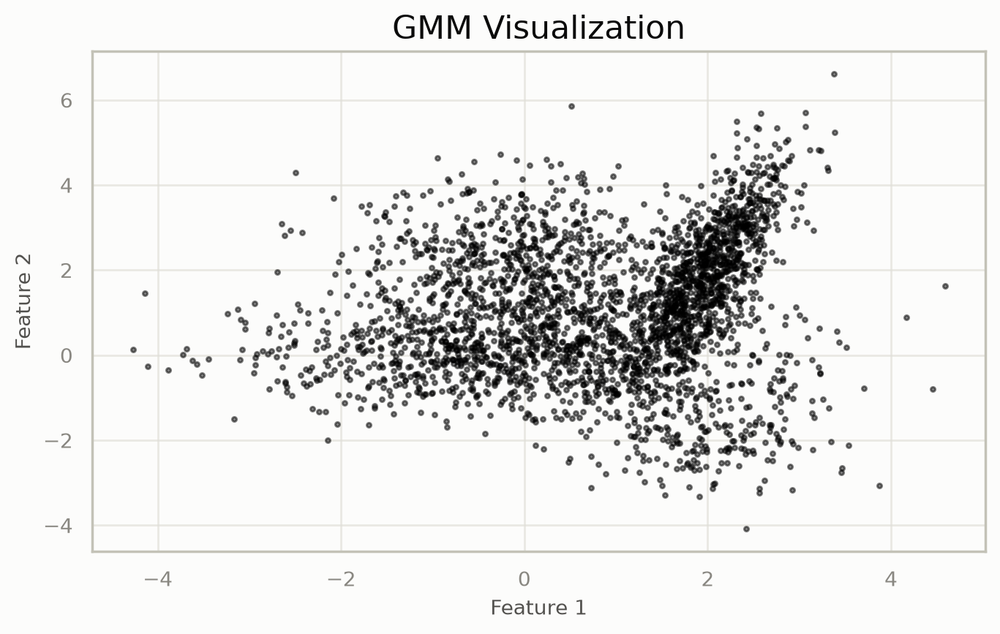

In [ ]:
_nrows, _ncols = (1, 1)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _ax = plt.subplots(nrows=_nrows, ncols=_ncols, figsize=_figsize)
plot_gmm(X, gmm=None, show_points=True, point_size=5, point_alpha=0.5, point_color='auto', color_by_cluster=False, true_labels=None, match_labels_to_true=False, cluster_colors='turbo', show_incorrect_predictions=False, log_probs=None, colormap='viridis', colorbar_label='Log Probability', show_ellipses=True, ellipse_std_devs=[1, 2, 3], ellipse_alpha=0.5, ellipse_colors='auto', ellipse_fill=True, ellipse_line_style='dotted', ellipse_line_width=2, ellipse_line_color='black', ellipse_line_alpha=0.5, show_means=True, mean_marker='h', mean_size=25, mean_color='black', show_initial_means=False, initial_mean_marker='H', initial_mean_size=25, initial_mean_color='red', scale_alpha_by_weight=False, scale_size_by_weight=False, ax=_ax, title='GMM Visualization', xlabel='Feature 1', ylabel='Feature 2', legend=True, legend_labels=None)
plt.tight_layout()
plt.gcf()

## Simple Data Points Without GMM

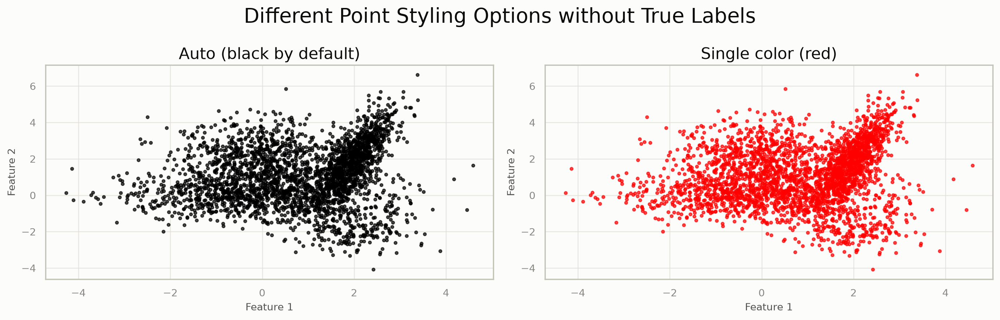

In [ ]:
_nrows, _ncols = (1, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axes = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axes = _axes.flatten()
_fig.suptitle('Different Point Styling Options without True Labels')
point_color_options = [('auto', 'Auto (black by default)', {}), ('red', 'Single color (red)', {})]
# Different point colors
for _i, (color_option, _title, extra_params) in enumerate(point_color_options):
    plot_gmm(X, gmm=None, point_color=color_option, point_size=8, point_alpha=0.7, title=_title, show_ellipses=False, show_means=False, ax=_axes[_i], **extra_params)
plt.tight_layout()
plt.gcf()

## Cluster Coloring with True Labels

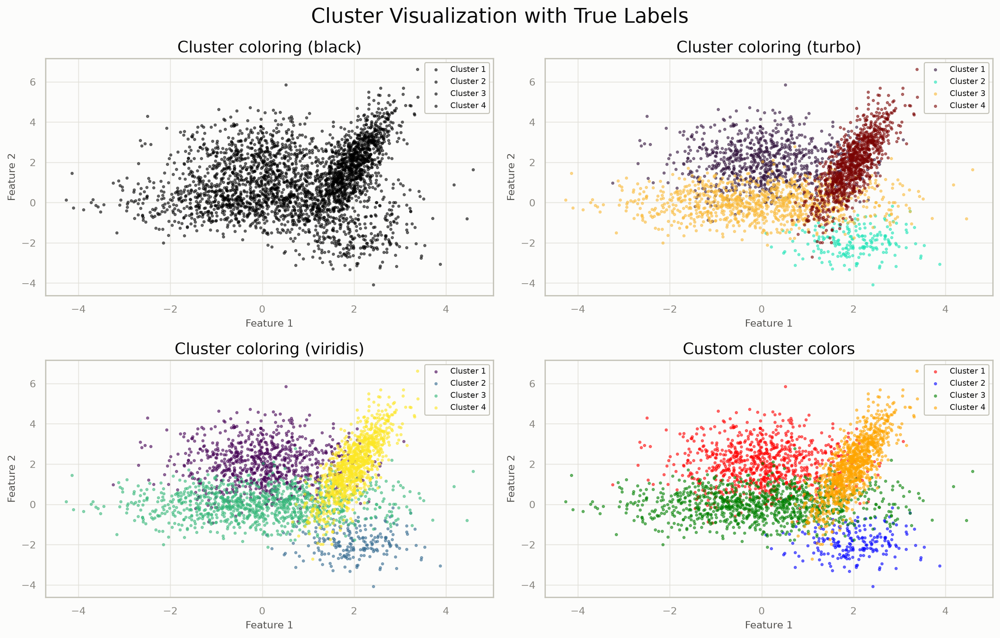

In [ ]:
_nrows, _ncols = (2, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axes = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axes = _axes.flatten()
_fig.suptitle('Cluster Visualization with True Labels')
cluster_options = [(True, 'black', 'Cluster coloring (black)'), (True, 'turbo', 'Cluster coloring (turbo)'), (True, 'viridis', 'Cluster coloring (viridis)'), (True, ['red', 'blue', 'green', 'orange'], 'Custom cluster colors')]
for _i, (color_by_cluster, cluster_colors, _title) in enumerate(cluster_options):
    plot_gmm(X, gmm=None, color_by_cluster=color_by_cluster, true_labels=labels, cluster_colors=cluster_colors, title=_title, show_ellipses=False, show_means=False, ax=_axes[_i])
plt.tight_layout()
plt.gcf()

## Confidence Ellipses

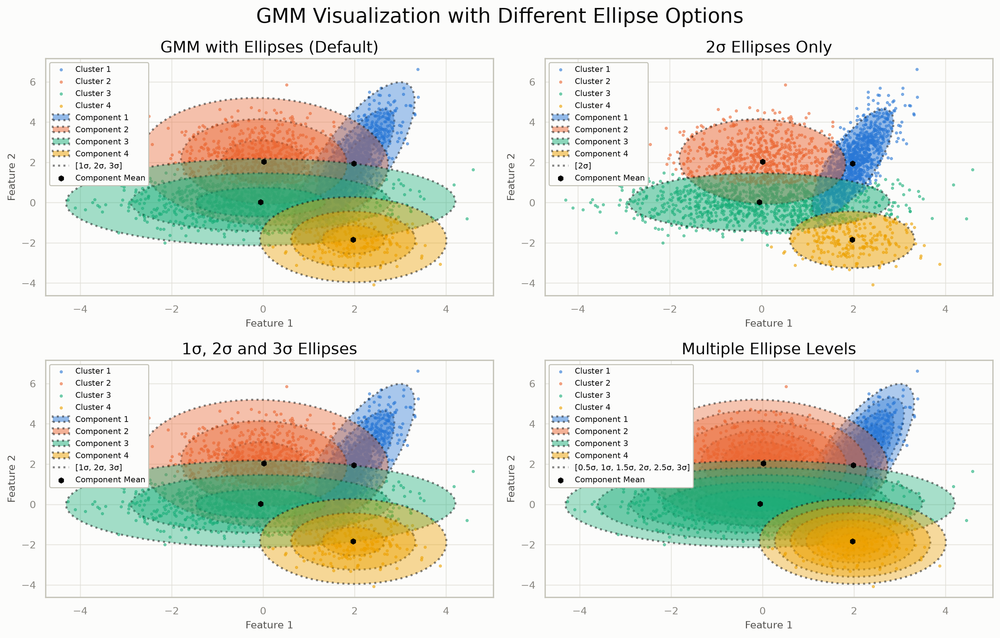

In [ ]:
_nrows, _ncols = (2, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axes = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axes = _axes.flatten()
_fig.suptitle('GMM Visualization with Different Ellipse Options')
plot_gmm(X, gmm=gmm, color_by_cluster=True, title='GMM with Ellipses (Default)', ax=_axes[0])
# Basic GMM with ellipses
plot_gmm(X, gmm=gmm, color_by_cluster=True, ellipse_std_devs=[2], title='2σ Ellipses Only', ax=_axes[1])
plot_gmm(X, gmm=gmm, color_by_cluster=True, ellipse_std_devs=[1, 2, 3], title='1σ, 2σ and 3σ Ellipses', ax=_axes[2])
plot_gmm(X, gmm=gmm, color_by_cluster=True, ellipse_std_devs=[0.5, 1, 1.5, 2, 2.5, 3], title='Multiple Ellipse Levels', ax=_axes[3])
plt.tight_layout()
# Different ellipse standard deviations
plt.gcf()

## Ellipse Styling Options

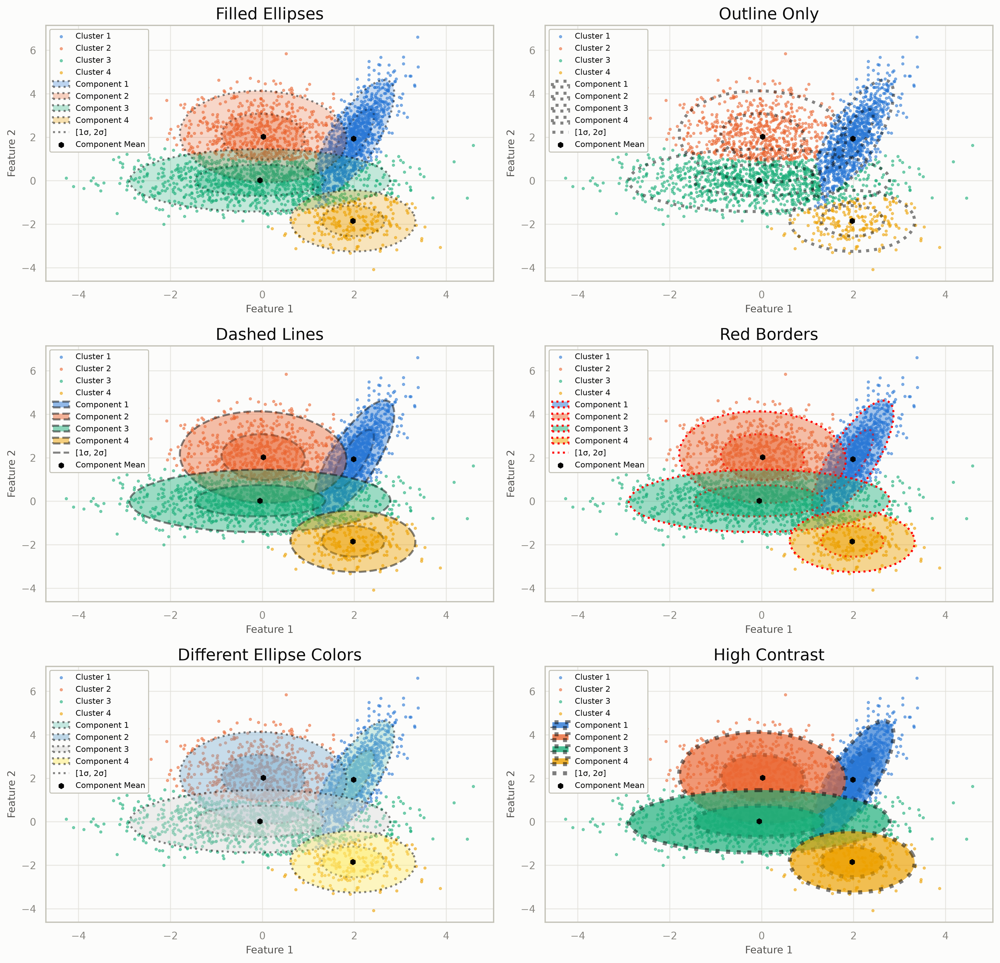

In [ ]:
_nrows, _ncols = (3, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axes = plt.subplots(_nrows, _ncols, figsize=_figsize, dpi=150)  # the module default (300 dpi) makes this grid too large for the notebook output
_axes = _axes.flatten()
ellipse_styles = [{'ellipse_fill': True, 'ellipse_alpha': 0.3, 'title': 'Filled Ellipses'}, {'ellipse_fill': False, 'ellipse_line_width': 3, 'title': 'Outline Only'}, {'ellipse_line_style': 'dashed', 'ellipse_line_width': 2, 'title': 'Dashed Lines'}, {'ellipse_line_color': 'red', 'ellipse_line_alpha': 1.0, 'title': 'Red Borders'}, {'ellipse_colors': 'Set3', 'title': 'Different Ellipse Colors'}, {'ellipse_alpha': 0.8, 'ellipse_line_width': 4, 'ellipse_line_color': 'black', 'title': 'High Contrast'}]
# Different ellipse styling options
for _i, style_options in enumerate(ellipse_styles):
    _title = style_options.pop('title')
    plot_gmm(X, gmm=gmm, color_by_cluster=True, ellipse_std_devs=[1, 2], title=_title, ax=_axes[_i], **style_options)
plt.tight_layout()
plt.gcf()

## Log Probability Visualization

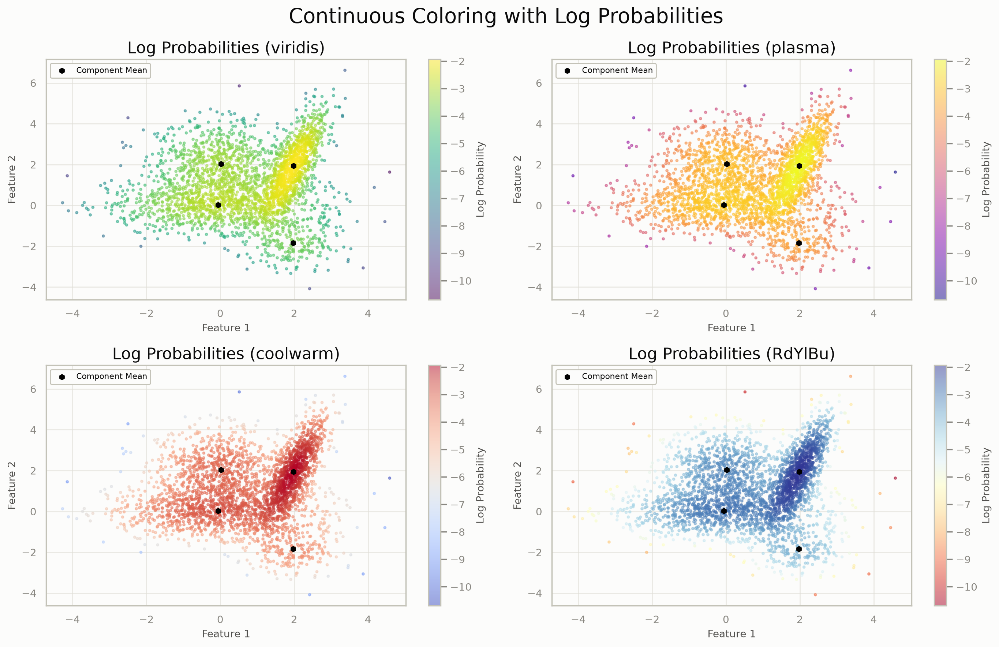

In [ ]:
_nrows, _ncols = (2, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axes = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axes = _axes.flatten()
_fig.suptitle('Continuous Coloring with Log Probabilities')
colormaps = ['viridis', 'plasma', 'coolwarm', 'RdYlBu']
# Different continuous coloring options
for _i, cmap in enumerate(colormaps):
    plot_gmm(X, gmm=gmm, log_probs=log_probs, colormap=cmap, colorbar_label='Log Probability', title=f'Log Probabilities ({cmap})', show_ellipses=False, ax=_axes[_i])
plt.tight_layout()
plt.gcf()

## Mean Markers and Initial Means

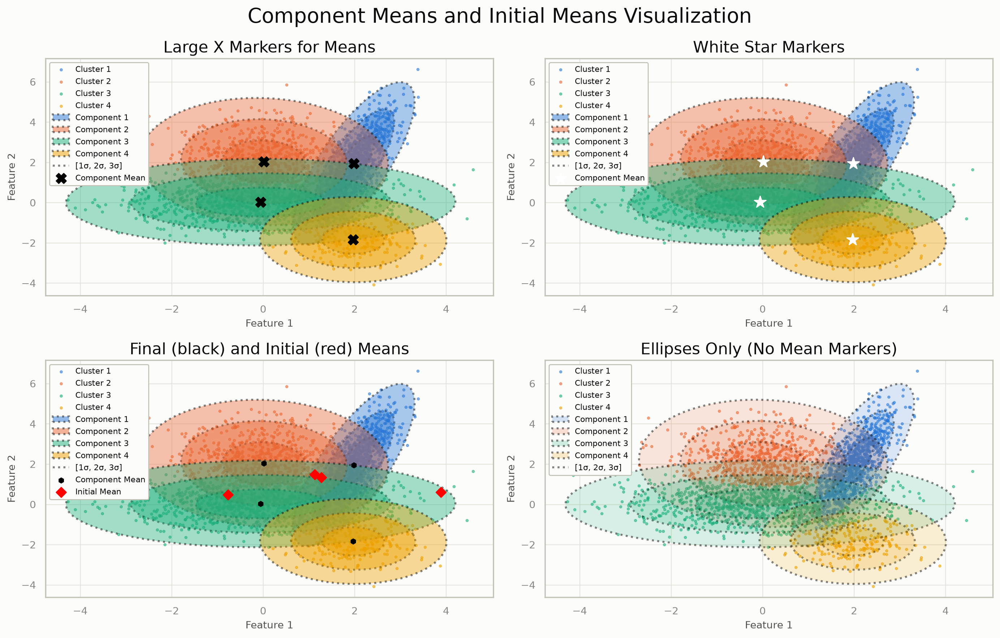

In [ ]:
_nrows, _ncols = (2, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axes = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axes = _axes.flatten()
_fig.suptitle('Component Means and Initial Means Visualization')
plot_gmm(X, gmm=gmm, color_by_cluster=True, show_means=True, mean_marker='X', mean_size=100, mean_color='black', title='Large X Markers for Means', ax=_axes[0])
# Different mean marker options
plot_gmm(X, gmm=gmm, color_by_cluster=True, show_means=True, mean_marker='*', mean_size=150, mean_color='white', title='White Star Markers', ax=_axes[1])
plot_gmm(X, gmm=gmm, color_by_cluster=True, show_means=True, show_initial_means=True, initial_mean_marker='D', initial_mean_size=50, initial_mean_color='red', title='Final (black) and Initial (red) Means', ax=_axes[2])
plot_gmm(X, gmm=gmm, color_by_cluster=True, show_means=False, show_ellipses=True, ellipse_alpha=0.2, title='Ellipses Only (No Mean Markers)', ax=_axes[3])
plt.tight_layout()
# Show initial means if available
plt.gcf()

## Component Weight Visualization

Component weights: [0.33910155 0.2541849  0.33460063 0.07211291]


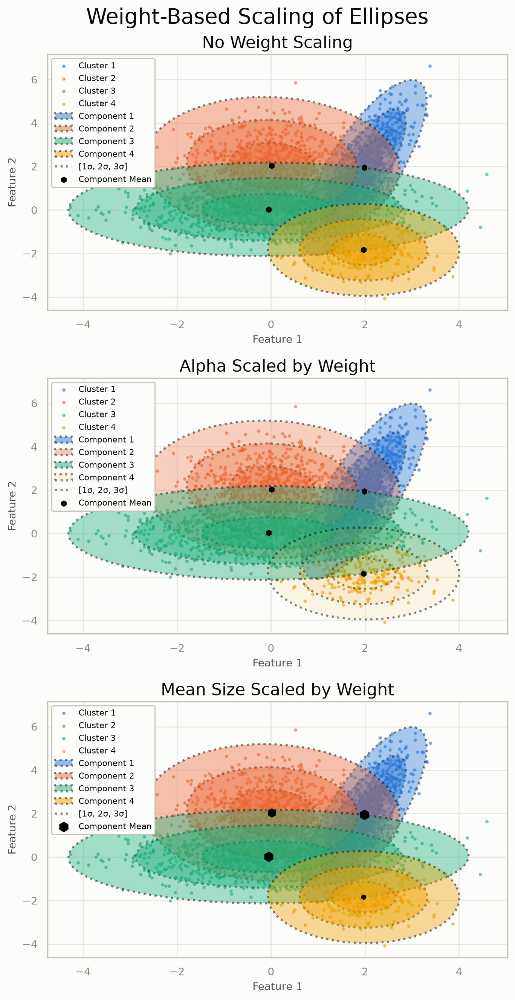

In [ ]:
_nrows, _ncols = (3, 1)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axes = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axes = _axes.flatten()
_fig.suptitle('Weight-Based Scaling of Ellipses')
plot_gmm(X, gmm=gmm, color_by_cluster=True, title='No Weight Scaling', ax=_axes[0])
# Regular visualization
plot_gmm(X, gmm=gmm, color_by_cluster=True, scale_alpha_by_weight=True, title='Alpha Scaled by Weight', ax=_axes[1])
plot_gmm(X, gmm=gmm, color_by_cluster=True, scale_size_by_weight=True, title='Mean Size Scaled by Weight', ax=_axes[2], mean_size=80)
plt.tight_layout()
# Print component weights for reference
print(f'Component weights: {gmm.weights_.detach().cpu().numpy()}')
plt.gcf()

## Prediction Accuracy Assessment

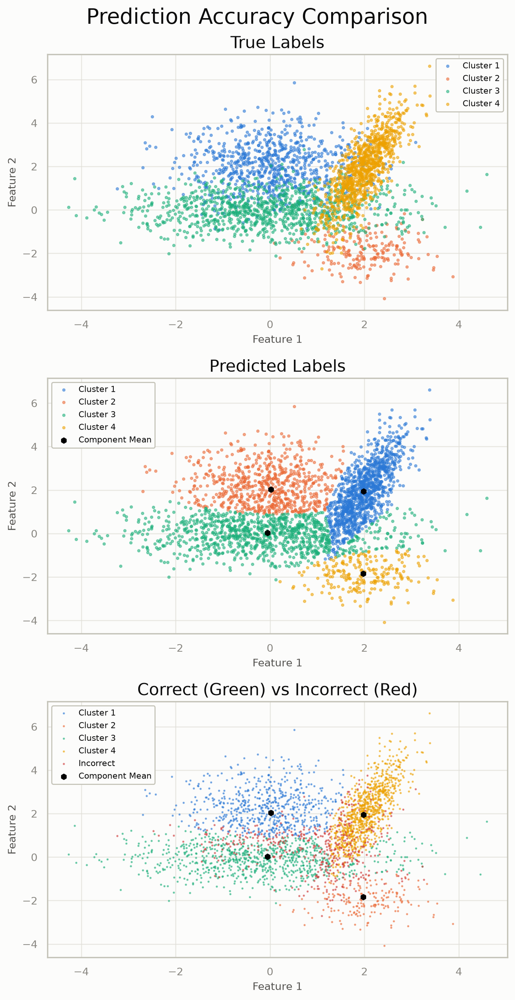

In [ ]:
_nrows, _ncols = (3, 1)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axes = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axes = _axes.flatten()
_fig.suptitle('Prediction Accuracy Comparison')
plot_gmm(X, gmm=None, color_by_cluster=True, true_labels=labels, title='True Labels', show_ellipses=False, ax=_axes[0])
# Show true labels
plot_gmm(X, gmm=gmm, color_by_cluster=True, title='Predicted Labels', show_ellipses=False, ax=_axes[1])
plot_gmm(X, gmm=gmm, true_labels=labels, show_incorrect_predictions=True, match_labels_to_true=True, title='Correct (Green) vs Incorrect (Red)', show_ellipses=False, ax=_axes[2])
plt.tight_layout()
# Show predicted labels
# Show correct vs incorrect predictions
plt.gcf()

## Overview of Different Visualization Combinations

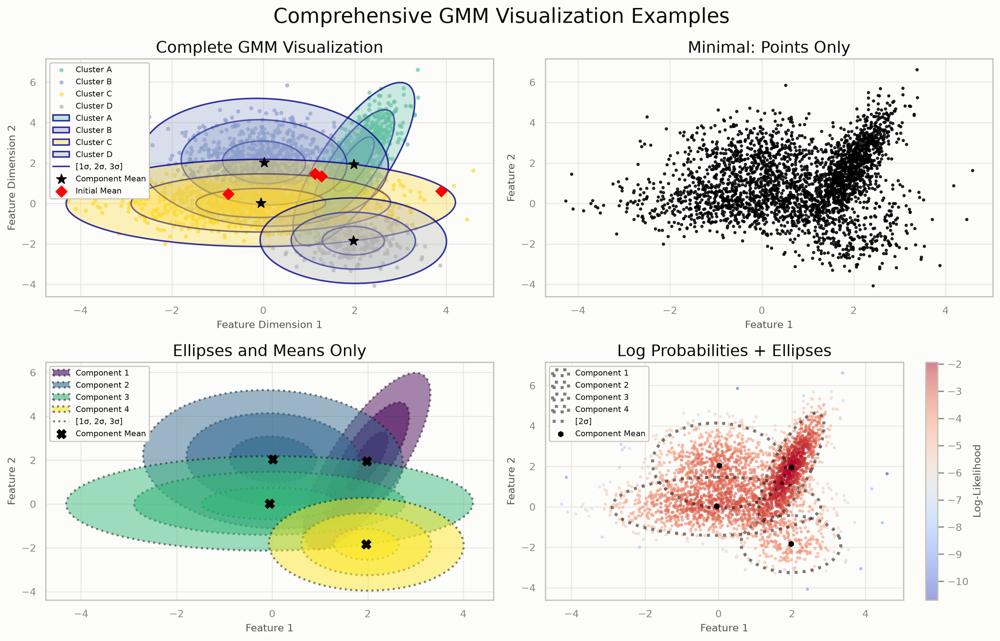

In [ ]:
_nrows, _ncols = (2, 2)
_figsize = dynamic_figsize(_nrows, _ncols)
_fig, _axes = plt.subplots(_nrows, _ncols, figsize=_figsize)
_axes = _axes.flatten()
_fig.suptitle('Comprehensive GMM Visualization Examples')
custom_labels = ['Cluster A', 'Cluster B', 'Cluster C', 'Cluster D']
# Custom legend labels
plot_gmm(X, gmm=gmm, show_points=True, point_size=10, point_alpha=0.6, point_color='auto', color_by_cluster=True, cluster_colors='Set2', legend_labels=custom_labels, show_ellipses=True, ellipse_std_devs=[1, 2, 3], ellipse_alpha=0.4, ellipse_fill=True, ellipse_line_style='solid', ellipse_line_width=1.5, ellipse_line_color='darkblue', ellipse_line_alpha=0.8, show_means=True, mean_marker='*', mean_size=100, mean_color='black', show_initial_means=True, initial_mean_marker='D', initial_mean_size=60, initial_mean_color='red', title='Complete GMM Visualization', xlabel='Feature Dimension 1', ylabel='Feature Dimension 2', ax=_axes[0])
plot_gmm(X, gmm=gmm, show_points=True, point_size=5, point_alpha=0.8, point_color='black', show_ellipses=False, show_means=False, legend=False, title='Minimal: Points Only', ax=_axes[1])
# Full-featured visualization
plot_gmm(X, gmm=gmm, show_points=False, show_ellipses=True, ellipse_std_devs=[1, 2, 3], ellipse_alpha=0.6, ellipse_colors='viridis', show_means=True, mean_marker='X', mean_size=80, title='Ellipses and Means Only', ax=_axes[2])
plot_gmm(X, gmm=gmm, log_probs=log_probs, colormap='coolwarm', colorbar_label='Log-Likelihood', show_ellipses=True, ellipse_std_devs=[2], ellipse_fill=False, ellipse_line_width=3, ellipse_line_color='black', title='Log Probabilities + Ellipses', ax=_axes[3])
plt.tight_layout()
# Minimal visualization
# Ellipses only
# Continuous coloring with ellipses
plt.gcf()

## Summary

- `plot_gmm(X, gmm=...)` draws the data, the fitted component means and nested covariance ellipses in one call; `gmm=None` plots data only.
- Points can be colored by true labels, predicted clusters, correctness (`show_incorrect_predictions`) or a continuous value such as `log_probs`.
- Ellipse levels (`ellipse_std_devs`), fill, line style, mean markers and initial-mean markers are all configurable.
- `scale_alpha_by_weight` / `scale_size_by_weight` make component weights visible, and every call accepts `ax=` so panels compose into grids.

**Next:** [04 -- Classification EM](04_cem.ipynb), or [08 -- PCA Plotting](08_pca_plotting.ipynb) for plotting high-dimensional models.